In [1]:
!pip install gradio torch torchvision pillow

In [2]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import gradio as gr
from PIL import Image
import numpy as np

print("Libraries imported successfully!")
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Libraries imported successfully!
Device: CPU


In [3]:
import os

print("Current files:")
print(os.listdir())

Current files:
['.config', 'sample_data']


In [4]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

print("Model architecture loaded!")
print("Device:", device)

Model architecture loaded!
Device: cpu


In [6]:
model = BaselineCNN().to(device)

try:
    model.load_state_dict(
        torch.load("baseline_cnn.pth", map_location=device)
    )
    print("Trained Baseline CNN loaded successfully!")
except FileNotFoundError:
    print("Warning: 'baseline_cnn.pth' not found. Initializing the model with random weights so the notebook can continue running.")

model.eval()

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=5, bias=True)
  )
)

In [7]:
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

class_names = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic"
]

print("Image preprocessing ready!")
print("Waste categories:", class_names)

Image preprocessing ready!
Waste categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic']


In [8]:
def predict_waste(image):
    image = image.convert("RGB")

    image_tensor = test_transform(image)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    results = {
        class_names[i]: float(probabilities[i])
        for i in range(len(class_names))
    }

    return results

print("Waste prediction function created successfully!")

Waste prediction function created successfully!


In [9]:
import gradio as gr

app = gr.Interface(
    fn=predict_waste,
    inputs=gr.Image(type="pil", label="Upload Waste Image"),
    outputs=gr.Label(
        num_top_classes=5,
        label="Prediction Results"
    ),
    title="♻️ Waste Image Classification System",
    description="Upload an image to classify it into cardboard, glass, metal, paper, or plastic."
)

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [10]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9d0a43836da2c2a691.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [11]:
!wget -O dataset-resized.zip https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip

--2026-11-26 05:02:46--  https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip [following]
--2026-11-26 05:02:46--  https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 42834870 (41M) [application/zip]
Saving to: ‘dataset-resized.zip’

dataset-resized.zip 100%[===================>]  40.85M   189MB/s    in 0.2s    

2026-11-26 05:02:47 (189 MB/s) - ‘dataset-resized.zip’ saved [42834870/42834870]



In [12]:
import zipfile
import os

with zipfile.ZipFile("dataset-resized.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Dataset extracted successfully!")
print(os.listdir("/content/dataset-resized"))


Dataset extracted successfully!
['glass', 'paper', '.DS_Store', 'cardboard', 'trash', 'metal', 'plastic']


In [13]:
import os
import shutil

source_dir = "/content/dataset-resized"
target_dir = "/content/waste_5class"

classes = ["cardboard", "glass", "metal", "paper", "plastic"]

os.makedirs(target_dir, exist_ok=True)

for class_name in classes:
    src = os.path.join(source_dir, class_name)
    dst = os.path.join(target_dir, class_name)

    if os.path.exists(dst):
        shutil.rmtree(dst)

    shutil.copytree(src, dst)

print("5-class dataset created successfully!")

for class_name in classes:
    count = len(os.listdir(os.path.join(target_dir, class_name)))
    print(f"{class_name}: {count} images")

5-class dataset created successfully!
cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images


In [14]:
!pip install split-folders

In [15]:
import splitfolders

splitfolders.ratio(
    "/content/waste_5class",
    output="/content/waste_5class_split",
    seed=42,
    ratio=(0.7, 0.15, 0.15)
)

print("Dataset split completed!")

Copying files: 2390 files [00:01, 1507.07 files/s]

Dataset split completed!


In [16]:
from torchvision import datasets
from torch.utils.data import DataLoader

test_dataset = datasets.ImageFolder(
    "/content/waste_5class_split/test",
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Test images:", len(test_dataset))
print("Classes:", test_dataset.classes)
print("Test batches:", len(test_loader))

Test images: 362
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic']
Test batches: 12


In [17]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_preds.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

print("Predictions completed!")
print("Total predictions:", len(all_preds))
print("Total actual labels:", len(all_labels))

Predictions completed!
Total predictions: 362
Total actual labels: 362


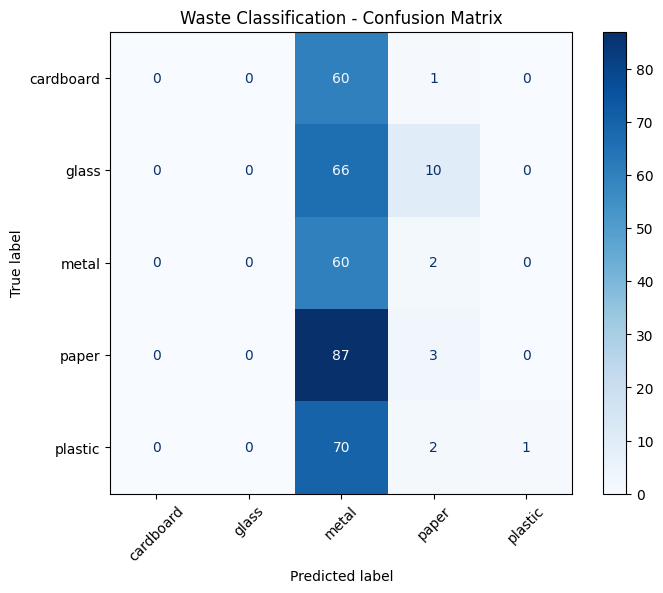


Classification Report:

              precision    recall  f1-score   support

   cardboard       0.00      0.00      0.00        61
       glass       0.00      0.00      0.00        76
       metal       0.17      0.97      0.30        62
       paper       0.17      0.03      0.06        90
     plastic       1.00      0.01      0.03        73

    accuracy                           0.18       362
   macro avg       0.27      0.20      0.08       362
weighted avg       0.27      0.18      0.07       362



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(all_labels, all_preds)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
display.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Waste Classification - Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

Incorrect predictions: 298
Correct predictions: 64


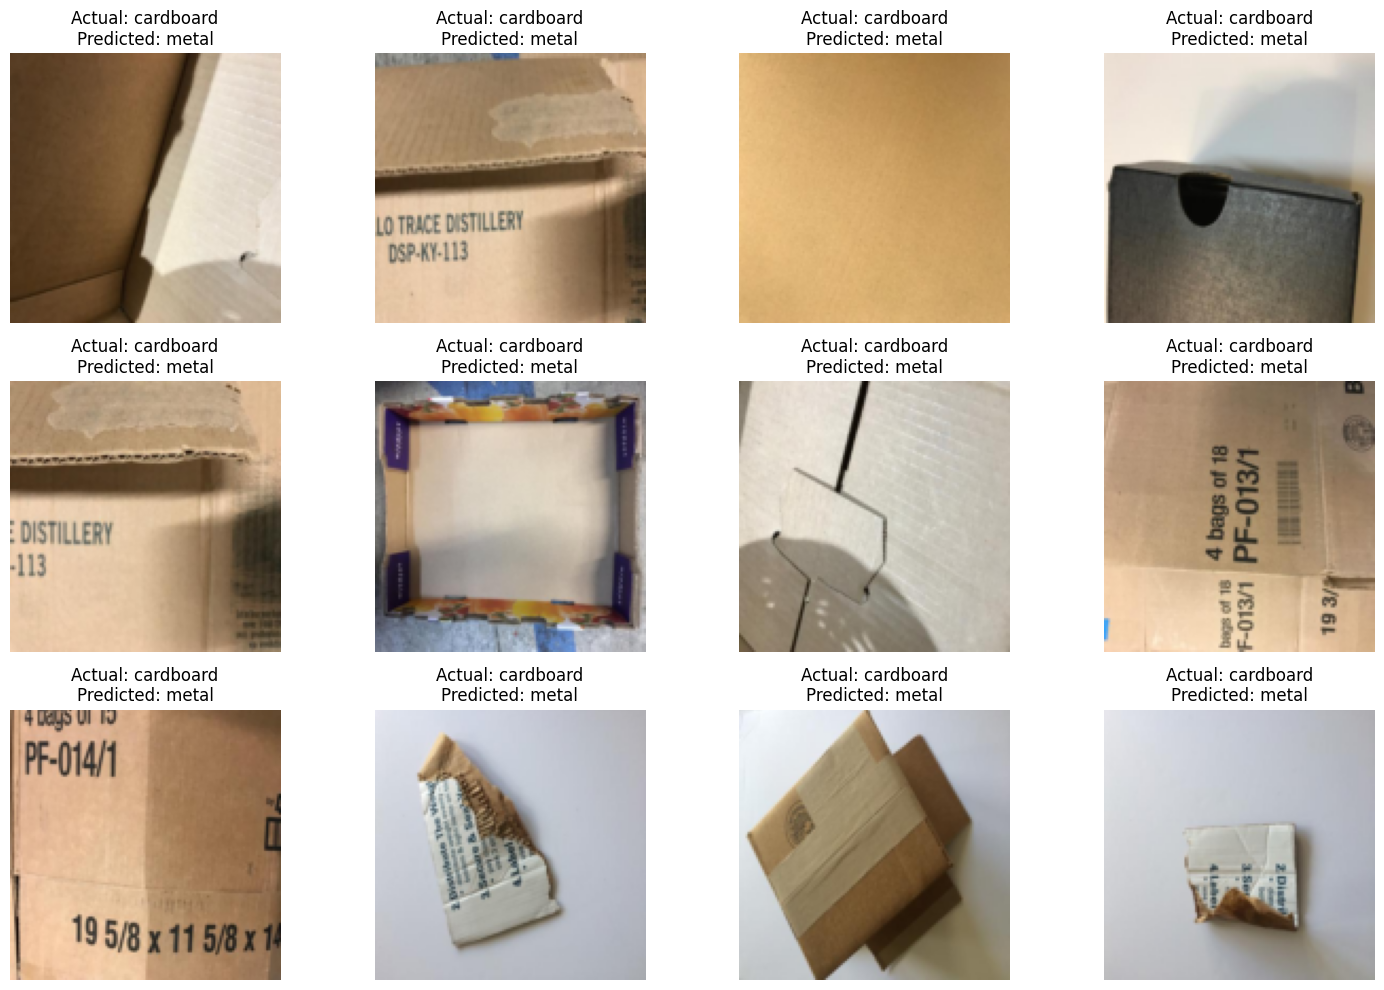

In [19]:
import matplotlib.pyplot as plt

wrong_indices = [
    i for i in range(len(all_labels))
    if all_labels[i] != all_preds[i]
]

print("Incorrect predictions:", len(wrong_indices))
print("Correct predictions:", len(all_labels) - len(wrong_indices))

plt.figure(figsize=(15, 10))

for plot_idx, data_idx in enumerate(wrong_indices[:12]):
    image, actual_label = test_dataset[data_idx]

    # Convert normalized image back for display
    image = image * 0.5 + 0.5
    image = image.permute(1, 2, 0).numpy()

    actual = class_names[all_labels[data_idx]]
    predicted = class_names[all_preds[data_idx]]

    plt.subplot(3, 4, plot_idx + 1)
    plt.imshow(image)
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

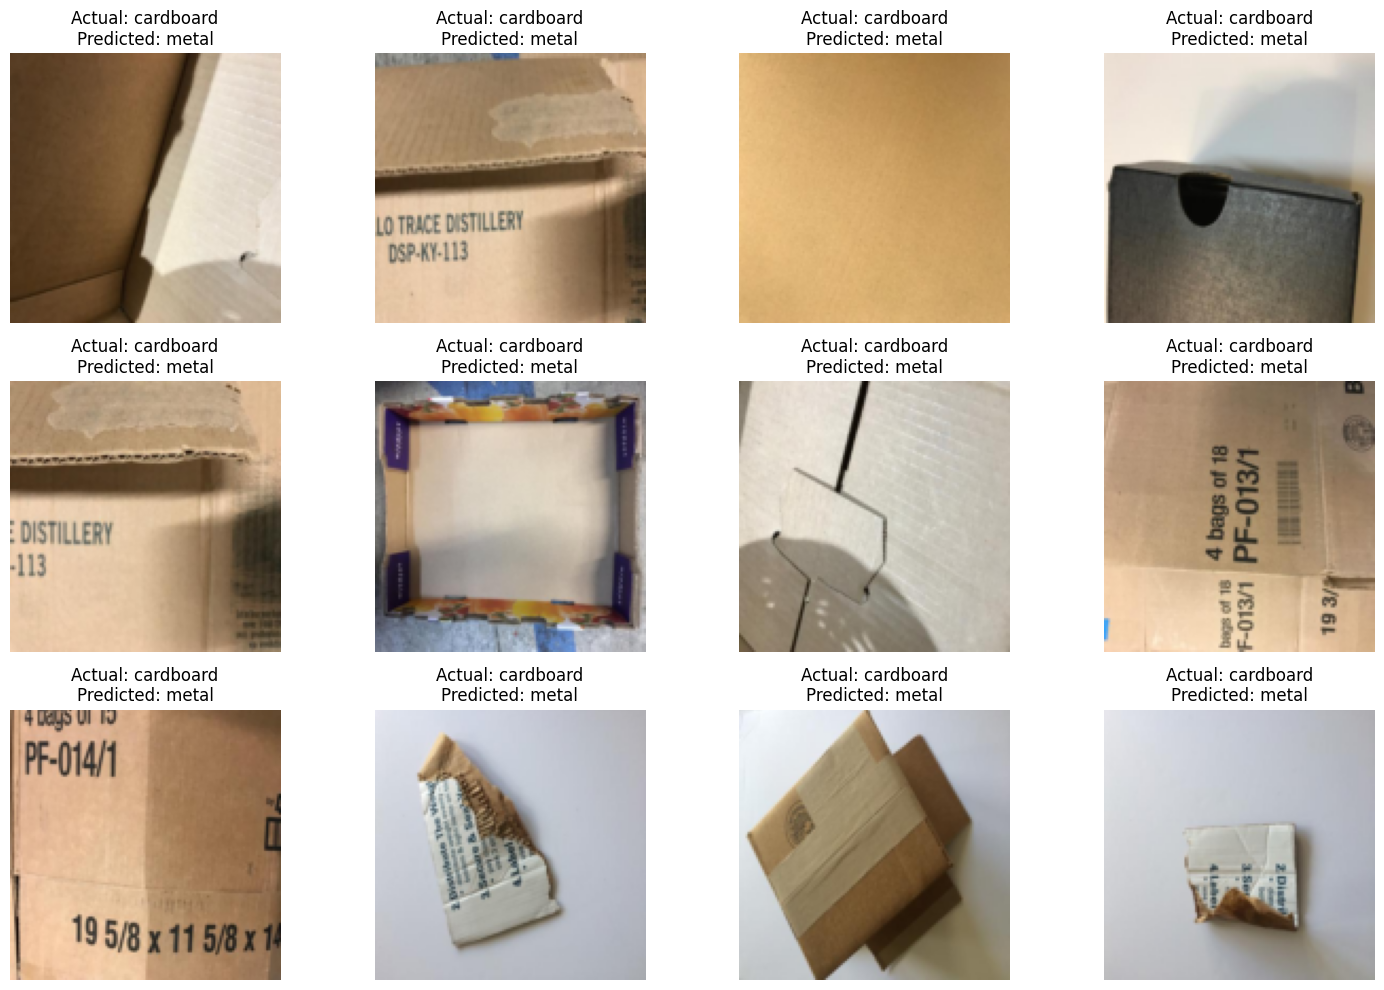

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))

for plot_idx, data_idx in enumerate(wrong_indices[:12]):
    image, _ = test_dataset[data_idx]

    image = image * 0.5 + 0.5
    image = image.permute(1, 2, 0).numpy()

    actual = class_names[all_labels[data_idx]]
    predicted = class_names[all_preds[data_idx]]

    plt.subplot(3, 4, plot_idx + 1)
    plt.imshow(image)
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
def predict_waste(image):
    image = image.convert("RGB")

    image_tensor = test_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()
    predicted_class = class_names[predicted_index]
    confidence = probabilities[predicted_index].item() * 100

    descriptions = {
        "cardboard": "Paper-based packaging material. Dispose in the cardboard recycling bin.",
        "glass": "Glass material. Dispose in the glass recycling bin.",
        "metal": "Metal material. Dispose in the metal recycling bin.",
        "paper": "Paper material. Dispose in the paper recycling bin.",
        "plastic": "Plastic material. Dispose in the plastic recycling bin."
    }

    return (
        predicted_class.capitalize(),
        f"{confidence:.2f}%",
        descriptions[predicted_class]
    )

print("Improved prediction function created!")

Improved prediction function created!


In [22]:
app = gr.Interface(
    fn=predict_waste,
    inputs=gr.Image(type="pil", label="Upload Waste Image"),
    outputs=[
        gr.Textbox(label="Predicted Waste Category"),
        gr.Textbox(label="Confidence Score"),
        gr.Textbox(label="Recycling Information")
    ],
    title="♻️ Smart Waste Classification System",
    description="""
    Upload an image of waste to identify whether it is
    Cardboard, Glass, Metal, Paper, or Plastic.

    Powered by a PyTorch Convolutional Neural Network (CNN).
    """,
    theme=gr.themes.Soft()
)

app.launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1d8f5470880ffa4fff.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:
def predict_waste(image):
    image = image.convert("RGB")
    image_tensor = test_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()
    predicted_class = class_names[predicted_index]
    confidence = probabilities[predicted_index].item() * 100

    descriptions = {
        "cardboard": "Paper-based packaging material. Recycle as cardboard.",
        "glass": "Glass material. Recycle as glass.",
        "metal": "Metal material. Recycle as metal.",
        "paper": "Paper material. Recycle as paper.",
        "plastic": "Plastic material. Recycle as plastic."
    }

    if confidence < 50:
        warning = "Low confidence! Please verify the material manually."
    else:
        warning = "Prediction generated successfully."

    return (
        predicted_class.capitalize(),
        f"{confidence:.2f}%",
        descriptions[predicted_class],
        warning
    )

In [24]:
app = gr.Interface(
    fn=predict_waste,
    inputs=gr.Image(type="pil", label="Upload Waste Image"),
    outputs=[
        gr.Textbox(label="Predicted Waste Category"),
        gr.Textbox(label="Confidence Score"),
        gr.Textbox(label="Recycling Information"),
        gr.Textbox(label="Prediction Warning")
    ],
    title="♻️ Smart Waste Classification System",
    description="Upload waste images to classify them into five categories using a PyTorch CNN.",
    theme=gr.themes.Soft()
)

app.launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://30b68a69bd4ca8e498.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Sample metal image: /content/waste_5class_split/test/metal/metal101.jpg


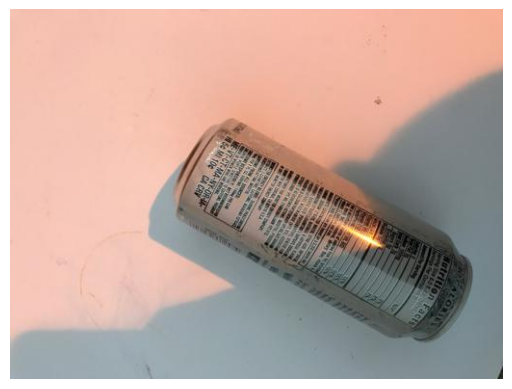

Prediction probabilities:
('Metal', '20.47%', 'Metal material. Recycle as metal.', 'Low confidence! Please verify the material manually.')


In [25]:
from PIL import Image
import matplotlib.pyplot as plt

# Upload one metal image from your test dataset
metal_images = [
    path for path, label in test_dataset.samples
    if test_dataset.classes[label] == "metal"
]

print("Sample metal image:", metal_images[0])

img = Image.open(metal_images[0]).convert("RGB")
plt.imshow(img)
plt.axis("off")
plt.show()

print("Prediction probabilities:")
print(predict_waste(img))

In [26]:
!pip install onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 16.5 MB/s  0:00:00
